# 04 – RQ4: predicting SLA breach at logging
**QM640 Data Analytics Capstone – Binesh Balakrishnan**

Only attributes known when the ticket is logged (first event record, `log_` columns) are used. Reassignment, reopen and update counts are excluded to avoid leakage.
Temporal split: earliest 70% of incidents (by `opened_at`) train, latest 30% test. Hyperparameters are tuned by 5-fold stratified cross-validation inside the training set.
Models: priority-only logistic regression (baseline), regularised logistic regression, random forest, XGBoost. H₀₄ is tested with the DeLong test.
Output: `results/rq4.json` and figures in `figures/`.

In [1]:
import os, subprocess
repo = '/content/QM640_data_analytics_capstone'
if not os.path.exists(repo):
    subprocess.run(['git', 'clone', '-q',
                    'https://github.com/binesh29/QM640_data_analytics_capstone.git', repo], check=True)
os.chdir(os.path.join(repo, 'notebooks'))
os.makedirs('../figures', exist_ok=True); os.makedirs('../results', exist_ok=True)

In [2]:
os.makedirs('../src', exist_ok=True)
with open('../src/plot_style.py', 'w') as f:
    f.write('''import matplotlib as mpl
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
def apply():
    mpl.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': INK2,
        'axes.labelcolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
        'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
        'grid.linewidth': 0.8, 'axes.axisbelow': True, 'xtick.color': INK2, 'ytick.color': INK2,
        'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'lines.linewidth': 2})
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5) / d
    return c - h, c + h
''')
print(os.listdir('../src'))

['sample_size.py', 'plot_style.py']


In [3]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, brier_score_loss, confusion_matrix, roc_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
sys.path.insert(0, '../src'); import plot_style as ps; ps.apply()
warnings.filterwarnings('ignore')
SEED = 42; FIG = Path('../figures'); R = {}

## 1. Features at logging and temporal split

In [4]:
inc = pd.read_csv('../data/processed/incidents.csv', parse_dates=['opened_at']).sort_values('opened_at').reset_index(drop=True)
CAT = ['log_priority', 'log_impact', 'log_urgency', 'log_category', 'log_subcategory', 'log_u_symptom',
       'log_contact_type', 'log_location', 'log_assignment_group', 'log_notify']
for c in CAT: inc[c] = inc[c].fillna('Missing').astype(str)
inc['log_u_priority_confirmation'] = inc['log_u_priority_confirmation'].astype(int)
inc['cmdb_ci_missing'] = inc['log_cmdb_ci'].isna().astype(int)
inc['hour_sin'] = np.sin(2 * np.pi * inc['log_hour'] / 24); inc['hour_cos'] = np.cos(2 * np.pi * inc['log_hour'] / 24)
inc['weekend'] = (inc['log_dayofweek'] >= 5).astype(int)
inc['dow'] = inc['log_dayofweek'].astype(str)
cut = int(len(inc) * 0.70)
tr, te = inc.iloc[:cut].copy(), inc.iloc[cut:].copy()
# caller frequency: number of training-period incidents from the same caller (computed on train only)
freq = tr['log_caller_id'].value_counts()
for d in (tr, te): d['caller_freq'] = np.log1p(d['log_caller_id'].map(freq).fillna(0))
y_tr, y_te = tr['sla_breach'].values, te['sla_breach'].values
R['split'] = {'cut_time': str(inc['opened_at'].iloc[cut]), 'n_train': len(tr), 'n_test': len(te),
              'breach_train': round(y_tr.mean(), 3), 'breach_test': round(y_te.mean(), 3),
              'test_breaches': int(y_te.sum()), 'test_met': int((1 - y_te).sum())}
print(R['split'])

{'cut_time': '2016-05-02 11:30:00', 'n_train': 17442, 'n_test': 7476, 'breach_train': np.float64(0.423), 'breach_test': np.float64(0.233), 'test_breaches': 1741, 'test_met': 5735}


In [5]:
CAT_ALL = CAT + ['dow']
NUM = ['caller_freq', 'hour_sin', 'hour_cos', 'weekend', 'log_u_priority_confirmation', 'cmdb_ci_missing']
FEATS = CAT_ALL + NUM
def prep(scale):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=True), CAT_ALL),
        ('num', StandardScaler() if scale else 'passthrough', NUM)])
Xtr, Xte = tr[FEATS], te[FEATS]
n_cols = prep(True).fit(Xtr).transform(Xtr).shape[1]
R['n_features_raw'] = len(FEATS); R['n_features_encoded'] = int(n_cols); print(len(FEATS), 'features ->', n_cols, 'encoded columns')

17 features -> 255 encoded columns


## 2. Models, tuned by 5-fold stratified CV on the training set (AUC)

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
pw = (1 - y_tr.mean()) / y_tr.mean()
specs = {
  'Baseline: priority-only LR': (Pipeline([('p', ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), ['log_priority'])])),
                                           ('m', LogisticRegression(class_weight='balanced', max_iter=1000))]), {}),
  'Regularised LR': (Pipeline([('p', prep(True)), ('m', LogisticRegression(class_weight='balanced', max_iter=3000, solver='liblinear'))]),
                     {'m__C': [0.03, 0.1, 0.3, 1.0], 'm__penalty': ['l1', 'l2']}),
  'Random forest': (Pipeline([('p', prep(False)), ('m', RandomForestClassifier(n_estimators=400, class_weight='balanced_subsample',
                                                                              n_jobs=-1, random_state=SEED))]),
                    {'m__min_samples_leaf': [2, 5, 10], 'm__max_features': ['sqrt', 0.2]}),
  'XGBoost': (Pipeline([('p', prep(False)), ('m', XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw,
                                                                eval_metric='logloss', random_state=SEED, n_jobs=4, tree_method='hist'))]),
              {'m__max_depth': [3, 5, 7], 'm__learning_rate': [0.03, 0.1]}),
}
fitted, cvres = {}, {}
for name, (pipe, grid) in specs.items():
    gs = GridSearchCV(pipe, grid or {'m__C': [1.0]}, scoring='roc_auc', cv=cv, n_jobs=1, refit=True)
    gs.fit(Xtr, y_tr); fitted[name] = gs.best_estimator_
    cvres[name] = {'cv_auc': round(gs.best_score_, 3), 'cv_auc_sd': round(gs.cv_results_['std_test_score'][gs.best_index_], 3),
                   'best_params': {k.replace('m__', ''): v for k, v in gs.best_params_.items()} if grid else {}}
    print(name, cvres[name])
R['cv'] = cvres

Baseline: priority-only LR {'cv_auc': np.float64(0.533), 'cv_auc_sd': np.float64(0.001), 'best_params': {}}
Regularised LR {'cv_auc': np.float64(0.768), 'cv_auc_sd': np.float64(0.004), 'best_params': {'C': 1.0, 'penalty': 'l1'}}
Random forest {'cv_auc': np.float64(0.79), 'cv_auc_sd': np.float64(0.003), 'best_params': {'max_features': 'sqrt', 'min_samples_leaf': 2}}
XGBoost {'cv_auc': np.float64(0.786), 'cv_auc_sd': np.float64(0.004), 'best_params': {'learning_rate': 0.1, 'max_depth': 5}}


## 3. Test-set evaluation and DeLong test

In [7]:
def delong(y, s1, s2=None):
    # Fast DeLong (Sun & Xu, 2014): AUCs, their covariance; returns auc1, se1, (auc2, se2, z, p_one_sided) if s2
    pos, neg = y == 1, y == 0; m, n = pos.sum(), neg.sum()
    def comp(s):
        from scipy.stats import rankdata
        tx, ty, tz = rankdata(s[pos]), rankdata(s[neg]), rankdata(np.r_[s[pos], s[neg]])
        auc = (tz[:m].sum() - m * (m + 1) / 2) / (m * n)
        v01 = (tz[:m] - tx) / n; v10 = 1 - (tz[m:] - ty) / m
        return auc, v01, v10
    a1, v01a, v10a = comp(s1)
    if s2 is None:
        return a1, np.sqrt(np.var(v01a, ddof=1) / m + np.var(v10a, ddof=1) / n)
    a2, v01b, v10b = comp(s2)
    s01 = np.cov(np.vstack([v01a, v01b])); s10 = np.cov(np.vstack([v10a, v10b]))
    S = s01 / m + s10 / n; var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (a1 - a2) / np.sqrt(var)
    return a1, a2, z, 1 - norm.cdf(z), np.corrcoef(s1, s2)[0, 1]
scores, rows = {}, []
for name, mdl in fitted.items():
    s = mdl.predict_proba(Xte)[:, 1]; scores[name] = s; yhat = (s >= 0.5).astype(int)
    auc, se = delong(y_te, s)
    rows.append({'model': name, 'auc': round(auc, 3), 'auc_ci': [round(auc - 1.96 * se, 3), round(auc + 1.96 * se, 3)],
                 'pr_auc': round(average_precision_score(y_te, s), 3), 'precision': round(precision_score(y_te, yhat), 3),
                 'recall': round(recall_score(y_te, yhat), 3), 'f1': round(f1_score(y_te, yhat), 3),
                 'accuracy': round(accuracy_score(y_te, yhat), 3), 'brier': round(brier_score_loss(y_te, s), 3), **cvres[name]})
perf = pd.DataFrame(rows); R['test'] = rows
best = perf.iloc[1:].sort_values('auc', ascending=False)['model'].iloc[0]; R['best_model'] = best
a1, a2, z, p, r = delong(y_te, scores[best], scores['Baseline: priority-only LR'])
R['delong_best_vs_baseline'] = {'auc_best': round(a1, 3), 'auc_base': round(a2, 3), 'diff': round(a1 - a2, 3), 'z': round(z, 2), 'p_one_sided': float(p), 'score_corr': round(r, 2)}
R['delong_all_vs_baseline'] = {}
for nm in list(fitted)[1:]:
    a1_, a2_, z_, p_, _ = delong(y_te, scores[nm], scores['Baseline: priority-only LR'])
    R['delong_all_vs_baseline'][nm] = {'diff': round(a1_ - a2_, 3), 'z': round(z_, 2), 'p_one_sided': float(p_)}
cm = confusion_matrix(y_te, (scores[best] >= 0.5).astype(int)); R['confusion_best'] = cm.tolist()
print(R['delong_best_vs_baseline']); perf

{'auc_best': np.float64(0.784), 'auc_base': np.float64(0.552), 'diff': np.float64(0.232), 'z': np.float64(38.28), 'p_one_sided': 0.0, 'score_corr': np.float64(0.37)}


,model,auc,auc_ci,pr_auc,precision,recall,f1,accuracy,brier,cv_auc,cv_auc_sd,best_params
0,Baseline: priority-only LR,0.552,"[0.545, 0.558]",0.289,0.884,0.070,0.130,0.781,0.240,0.533,0.001,{}
1,Regularised LR,0.779,"[0.767, 0.791]",0.533,0.436,0.654,0.523,0.722,0.185,0.768,0.004,"{'C': 1.0, 'penalty': 'l1'}"
2,Random forest,0.784,"[0.772, 0.796]",0.535,0.445,0.657,0.531,0.729,0.181,0.790,0.003,"{'max_features': 'sqrt', 'min_samples_leaf': 2}"
3,XGBoost,0.751,"[0.739, 0.764]",0.496,0.409,0.617,0.492,0.703,0.190,0.786,0.004,"{'learning_rate': 0.1, 'max_depth': 5}"


### Figure: ROC curves on the temporal test set

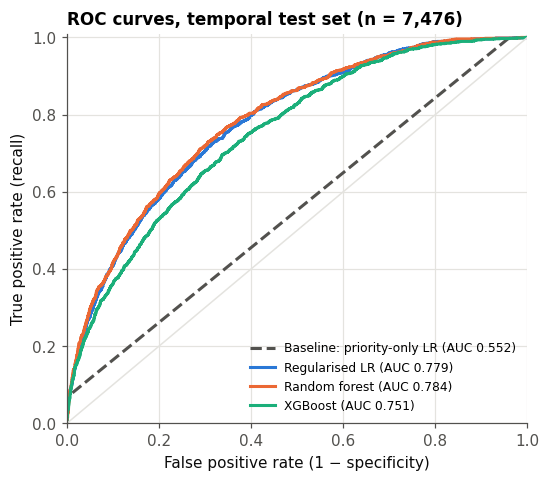

In [8]:
cols = [ps.INK2, ps.BLUE, ps.ORANGE, ps.AQUA]; styles = ['--', '-', '-', '-']
fig, ax = plt.subplots(figsize=(5.4, 4.6))
for (name, s), c, ls in zip(scores.items(), cols, styles):
    f, t, _ = roc_curve(y_te, s); a = perf.set_index('model').loc[name, 'auc']
    ax.plot(f, t, color=c, ls=ls, label=f'{name} (AUC {a:.3f})')
ax.plot([0, 1], [0, 1], color=ps.GRID, lw=1)
ax.set_xlabel('False positive rate (1 − specificity)'); ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curves, temporal test set (n = %s)' % f'{len(y_te):,}'); ax.legend(loc='lower right', fontsize=8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
fig.savefig(FIG / 'fig_roc_rq4.png'); plt.show()

## 4. Permutation importance of the best model (test set, AUC drop)

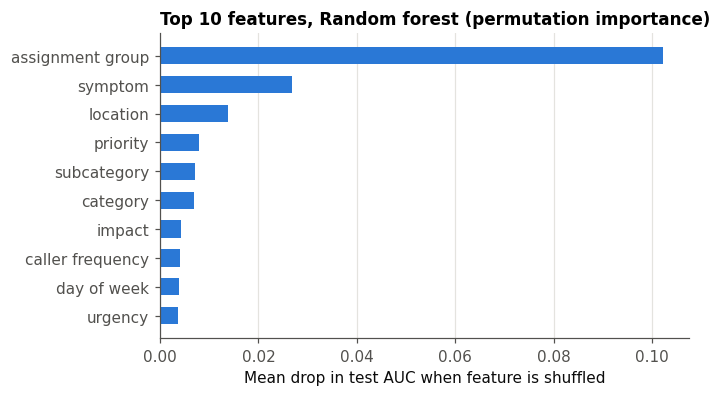

,0
log_assignment_group,0.102334
log_u_symptom,0.026756
log_location,0.013753
log_priority,0.007951
log_subcategory,0.007088
log_category,0.006821
log_impact,0.004202
caller_freq,0.004009
dow,0.003839
log_urgency,0.003725


In [9]:
pi = permutation_importance(fitted[best], Xte, y_te, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
R['importance'] = imp.round(4).to_dict()
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.barh(range(len(top)), top.values, color=ps.BLUE, height=0.6)
nice = {'dow': 'day of week', 'caller_freq': 'caller frequency', 'hour_sin': 'hour (sin)', 'hour_cos': 'hour (cos)', 'u_symptom': 'symptom', 'assignment_group': 'assignment group'}
ax.set_yticks(range(len(top)), [nice.get(c.replace('log_', ''), c.replace('log_', '').replace('_', ' ')) for c in top.index]); ax.set_xlabel('Mean drop in test AUC when feature is shuffled')
ax.set_title(f'Top 10 features, {best} (permutation importance)'); ax.grid(axis='y', visible=False)
fig.savefig(FIG / 'fig_importance_rq4.png'); plt.show(); imp.head(12)

## 5. Sensitivity: add knowledge-base flag at logging

In [10]:
CAT_S = CAT_ALL; NUM_S = NUM + ['log_knowledge']
tr['log_knowledge'] = tr['log_knowledge'].astype(int); te['log_knowledge'] = te['log_knowledge'].astype(int)
R['knowledge_at_logging_share'] = round(inc['log_knowledge'].astype(int).mean(), 3)
ms = fitted[best]
pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30), CAT_S),
                         ('num', StandardScaler() if 'LR' in best else 'passthrough', NUM_S)])
from sklearn.base import clone
sens = Pipeline([('p', pre), ('m', clone(ms.named_steps['m']))]).fit(tr[CAT_S + NUM_S], y_tr)
ss = sens.predict_proba(te[CAT_S + NUM_S])[:, 1]
R['sensitivity_knowledge_auc'] = round(roc_auc_score(y_te, ss), 3); print(R['sensitivity_knowledge_auc'], R['knowledge_at_logging_share'])

0.789 0.143


## 6. Sensitivity: stable period only (incidents opened from 21 March 2016)

In [11]:
st = inc[inc['opened_at'] >= '2016-03-21'].reset_index(drop=True)
c2 = int(len(st) * 0.70); tr2, te2 = st.iloc[:c2].copy(), st.iloc[c2:].copy()
f2 = tr2['log_caller_id'].value_counts()
for d in (tr2, te2): d['caller_freq'] = np.log1p(d['log_caller_id'].map(f2).fillna(0))
out = {'n_train': len(tr2), 'n_test': len(te2), 'breach_train': round(tr2['sla_breach'].mean(), 3), 'breach_test': round(te2['sla_breach'].mean(), 3)}
for name in ['Baseline: priority-only LR', best]:
    m = clone(fitted[name]).fit(tr2[FEATS], tr2['sla_breach'])
    out[name] = round(roc_auc_score(te2['sla_breach'], m.predict_proba(te2[FEATS])[:, 1]), 3)
R['sensitivity_stable_period'] = out; print(out)

{'n_train': 13308, 'n_test': 5704, 'breach_train': np.float64(0.262), 'breach_test': np.float64(0.23), 'Baseline: priority-only LR': np.float64(0.551), 'Random forest': np.float64(0.803)}


In [12]:
json.dump(R, open('../results/rq4.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o)); print('saved')

saved
